In [1]:
# Email Spam Detection using KNN and SVM

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

In [3]:
# 1. Load Dataset
df = pd.read_csv("emails.csv")

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nMissing Values:", df.isnull().sum().sum())

# 2. Preprocess Dataset
df = df.dropna()
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Target column is usually Prediction in this dataset
target = "Prediction" if "Prediction" in df.columns else df.columns[-1]

# Remove email ID column if present
X = df.drop(columns=[target, "Email No."], errors="ignore")
y = df[target]


First 5 Rows:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Dataset Shape: (5172, 3002)

Missing Values: 0


In [4]:
# Convert labels to integers
y = y.astype(int)

print("\nClass Distribution:")
print(y.value_counts())


Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [5]:
# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
# 4. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
# 5. K-Nearest Neighbors Model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

In [9]:
# 6. Support Vector Machine Model
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

In [10]:
# 7. Evaluate Models
def evaluate_model(name, actual, predicted):
    print("\n", name)
    print("Accuracy:", round(accuracy_score(actual, predicted), 4))
    print("Precision:", round(precision_score(actual, predicted, zero_division=0), 4))
    print("Recall:", round(recall_score(actual, predicted, zero_division=0), 4))
    print("F1 Score:", round(f1_score(actual, predicted, zero_division=0), 4))
    print("\nClassification Report:")
    print(classification_report(actual, predicted, zero_division=0))

evaluate_model("KNN Results", y_test, knn_pred)
evaluate_model("SVM Results", y_test, svm_pred)


 KNN Results
Accuracy: 0.8338
Precision: 0.6435
Recall: 0.9567
F1 Score: 0.7694

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       735
           1       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


 SVM Results
Accuracy: 0.9507
Precision: 0.9136
Recall: 0.9167
F1 Score: 0.9151

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



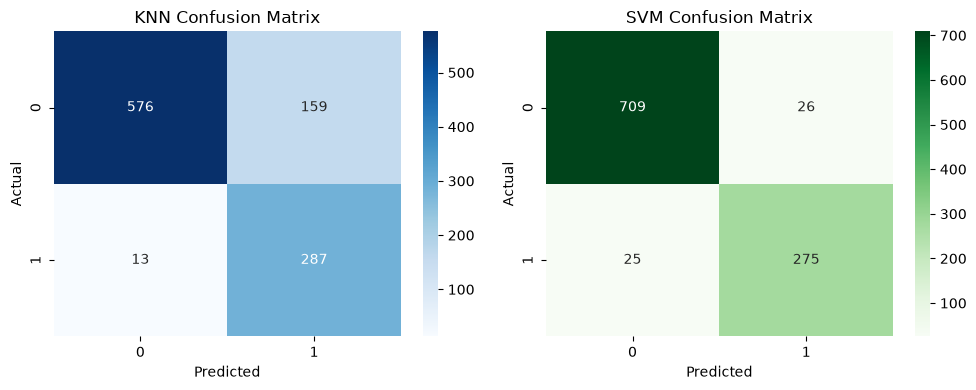

In [11]:
# 8. Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(
    confusion_matrix(y_test, knn_pred),
    annot=True, fmt="d", cmap="Blues", ax=axes[0]
)
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, svm_pred),
    annot=True, fmt="d", cmap="Greens", ax=axes[1]
)
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [12]:
# 9. Compare Models
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Precision": [
        precision_score(y_test, knn_pred, zero_division=0),
        precision_score(y_test, svm_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, knn_pred, zero_division=0),
        recall_score(y_test, svm_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, knn_pred, zero_division=0),
        f1_score(y_test, svm_pred, zero_division=0)
    ]
})

print("\nModel Comparison:")
print(results.to_string(index=False))


Model Comparison:
Model  Accuracy  Precision   Recall  F1 Score
  KNN  0.833816   0.643498 0.956667  0.769437
  SVM  0.950725   0.913621 0.916667  0.915141


In [13]:
# 10. Best Model
if accuracy_score(y_test, knn_pred) > accuracy_score(y_test, svm_pred):
    print("\nKNN performs better based on accuracy.")
elif accuracy_score(y_test, svm_pred) > accuracy_score(y_test, knn_pred):
    print("\nSVM performs better based on accuracy.")
else:
    print("\nBoth models have equal accuracy.")


SVM performs better based on accuracy.
